# 4.2_variance 方差差异 — sub-01 ses-retest

标准差缩放会改变振幅信息与弱信号权重；常量体素不能静默除零。

按run有效时点使用 sample z-score（ddof=1）并排除低方差体素；是否保留振幅由任务决定。

真实输入、处理前后、可复用关键代码、可视化与量化均在下面。两次采集仅教学few-shot，不能确定最优方法。

**限制：** 与已安装 Nilearn 的数值一致性将实测；不推断模型性能。

In [1]:
from pathlib import Path
import sys, os, importlib.util, json, inspect
ROOT = Path(os.environ["FMRI_REFERENCE_ROOT"]).resolve() if "FMRI_REFERENCE_ROOT" in os.environ else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"fmri_reference"/"core.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from repository or set FMRI_REFERENCE_ROOT")
sys.path.insert(0, str(ROOT))
from fmri_reference.core import load_sample
spec = importlib.util.spec_from_file_location("category_reference", ROOT / "04_signal_scale_inconsistency/4.2_variance/src/reference.py")
reference = importlib.util.module_from_spec(spec); spec.loader.exec_module(reference)
SESSION = "retest"
sample = load_sample(ROOT, SESSION)
print("REAL INPUT:", sample["path"])
print(json.dumps(sample["geometry"], indent=2))
print({k:v for k,v in sample["timing"].items() if k != "onsets_seconds"})
print("before mean/std:", sample["signals"].mean(), sample["signals"].std(ddof=1))


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


REAL INPUT: /Users/liuxiang/fMRI-preprocess/standard-reference/data/ds000114/sub-01/ses-retest/func/sub-01_ses-retest_task-fingerfootlips_bold.nii.gz
{
  "shape": [
    64,
    64,
    30,
    184
  ],
  "orientation": [
    "L",
    "A",
    "S"
  ],
  "spacing_mm": [
    3.999999997183861,
    3.999999857818425,
    3.9999644753281265
  ],
  "qform_code": 1,
  "sform_code": 1,
  "qform_sform_disagree": false,
  "affine_ras_mm": [
    [
      -3.9941670894622803,
      -0.21387556195259094,
      -0.030091872438788414,
      131.2411651611328
    ],
    [
      -0.2149735540151596,
      3.9901509284973145,
      0.18016961216926575,
      -102.3945083618164
    ],
    [
      -0.02038651518523693,
      -0.18152596056461334,
      3.995791435241699,
      -46.10886001586914
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ]
}
{'tr_seconds': 2.5, 'sampling_hz': 0.4, 'nyquist_hz': 0.2, 'n_volumes': 184, 'sample_span_seconds': 457.5, 'nominal_duration_seconds': 460.0}
bef

## 关键函数与执行

所有源码可追踪。配准/生理/组织输入不存在时，不生成虚构校正结果。

In [2]:
print(inspect.getsource(reference.apply))

def scale(x,method='zscore'):
    x=timeseries(x);mu=x.mean(0);sd=x.std(0,ddof=1)
    if method=='center':return x-mu
    if method=='zscore':
        if (sd<=1e-12).any():raise ValueError('Constant features require explicit exclusion')
        return (x-mu)/sd
    if method=='psc':
        if (np.abs(mu)<=1e-8).any():raise ValueError('PSC requires nonzero pre-regression baseline')
        return 100*(x-mu)/np.abs(mu)
    if method=='robust':
        med=np.median(x,axis=0);mad=1.4826*np.median(np.abs(x-med),axis=0)
        if (mad<=1e-12).any():raise ValueError('Degenerate robust scale')
        return (x-med)/mad
    raise ValueError('Unknown scale method')



{
  "input": "data/ds000114/sub-01/ses-retest/func/sub-01_ses-retest_task-fingerfootlips_bold.nii.gz",
  "session": "retest",
  "kind": "variance",
  "tr_seconds": 2.5,
  "n_input": 184,
  "feature_scope": "128 deterministic voxels from estimated EPI mask, not full brain",
  "before": {
    "shape": [
      184,
      128
    ],
    "mean_abs": 1188.474312160326,
    "median_sample_std": 37.16732411570946,
    "q01": 179.0,
    "q99": 1848.0
  },
  "production_pipeline": "NOT_RUN",
  "scientific_best_method": "INSUFFICIENT_EVIDENCE",
  "nilearn_max_abs_error": 8.881784197001252e-15,
  "output_mean_max_abs": 7.0957732443433916e-15,
  "output_std_max_error": 2.220446049250313e-16,
  "after": {
    "shape": [
      184,
      128
    ],
    "mean_abs": 1.622126723402943e-15,
    "median_sample_std": 1.0,
    "q01": -1.9401763507064358,
    "q99": 2.1185536802096046
  },
  "evidence_status": "REAL_DATA_PRIMITIVE_EXECUTED",
  "limitations": [],
  "elapsed_seconds": 1.278545041976031
}


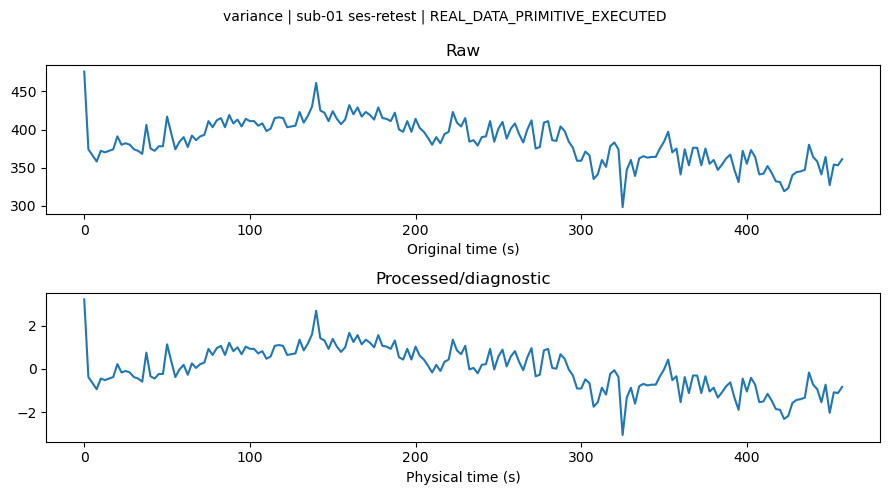

In [3]:
metrics, fig = reference.demonstrate(ROOT, SESSION, variant=1, outdir=ROOT/"04_signal_scale_inconsistency/4.2_variance/results/retest")
print(json.dumps(metrics, indent=2))
from IPython.display import display
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

## 常见错误与阻止机制

以下故意提供不满足科学前提的输入。报错是负对照，不是处理失败被掩盖。

In [4]:
try:
    reference.error_example("variance")
except (ValueError, FileNotFoundError) as e:
    print("EXPECTED REJECTION:", type(e).__name__, str(e))
else:
    raise AssertionError("Invalid scientific input was accepted")

EXPECTED REJECTION: ValueError Constant features require explicit exclusion


## 解释与后续验证

数值不变性/投影正交性只验证实现数学性质。更低DVARS、更高tSNR、更低配准目标值不是神经信号保真证明。正式推荐需同数据、固定参数、跨受试者的独立下游证据。详见本小类README、references和根目录验证报告。